In [1]:

import time
from pathlib import Path
import sys
sys.path.append(str(Path.cwd().parent))

import matplotlib.pyplot as plt
import numpy as np
import xarray as xr
import zarr
import json
import torch
from torch.utils.data import DataLoader
from torch.utils.data import Dataset
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import cartopy.crs as ccrs
import cartopy.feature as cfeature

from config import *
from src.data import get_valid_indices, WeatherDataset
from src.model import WeatherCNN
from src.evaluate import rsme


In [7]:
ds_normed_zarr = xr.open_zarr(DATA_DIR / "era5_ml_ready.zarr")

all_data = torch.tensor(
    ds_normed_zarr["data"].values,
    dtype=torch.float32
)

In [4]:
model=WeatherCNN()

model.load_state_dict(
    torch.load(
        "../models/best_weather_cnn.pt"
    )
)

<All keys matched successfully>

In [8]:
times = ds_normed_zarr.forecast_reference_time.values

test_indices = get_valid_indices(times, TEST_START, TEST_END)

test_indices   = test_indices[test_indices + 4 < len(all_data)]

test_dataset = WeatherDataset(all_data, test_indices)

test_loader = DataLoader(
    test_dataset,
    batch_size=32,
    shuffle=False
)

In [32]:
x, y = test_dataset[0]

with torch.no_grad():
    prediction = model(x.unsqueeze(0))

prediction = prediction.squeeze(0)

persistence = x[11].unsqueeze(0).repeat(4, 1, 1)

for i, horizon in enumerate([6, 12, 18, 24]):

    cnn_rmse = rmse(
        prediction[i],
        y[i]
    )

    persistence_rmse = rmse(
        persistence[i],
        y[i]
    )

    print(
        f"+{horizon:2d}h | "
        f"CNN: {cnn_rmse:.4f} | "
        f"Persistence: {persistence_rmse:.4f}"
    )

+ 6h | CNN: 0.3671 | Persistence: 0.1775
+12h | CNN: 0.4815 | Persistence: 0.8695
+18h | CNN: 0.3117 | Persistence: 0.5741
+24h | CNN: 0.3028 | Persistence: 0.3971


# forecast single day

In [ ]:
def get_valid_indices_day(times, day, hour=0):

    indices = []

    day = np.datetime64(day)
    print(day)

    for i in range(len(times) - 4):

        # All five states must exist
        sample_times = times[i:i+5]

        if sample_times[0] == day:
            print(i)
            if hour!=0:
                idx=int(i+hour/6)
            else:
                idx=i
            print(idx)
            indices.append(idx)

    return np.array(indices)

In [ ]:
def evaluate_single_forecast(
    model,
    dataset,
    sample_idx,
    temperature_std=None
):

    model.eval()

    x, y = dataset[sample_idx]

    with torch.no_grad():
        prediction = model(
            x.unsqueeze(0)
        ).squeeze(0)

    # Persistence forecast
    persistence = (
        x[11]
        .unsqueeze(0)
        .repeat(4, 1, 1)
    )

    horizons = [6, 12, 18, 24]

    print(
        f"Sample: {sample_idx}"
    )

    for i, horizon in enumerate(horizons):

        cnn_rmse = rmse(
            prediction[i],
            y[i]
        ).item()

        persistence_rmse = rmse(
            persistence[i],
            y[i]
        ).item()

        if temperature_std is not None:
            cnn_rmse *= temperature_std
            persistence_rmse *= temperature_std

        print(
            f"+{horizon:2d}h | "
            f"CNN = {cnn_rmse:.3f} | "
            f"Persistence = {persistence_rmse:.3f}"
        )

    return x, y, prediction, persistence

In [ ]:
# split for cnn and persistence

In [ ]:
# write to csv file

In [ ]:
x, truth, cnn, persistence = evaluate_single_forecast(
    model,
    test_dataset,
    sample_idx=0,
    temperature_std=stats['2t']['std']
)

/tmp/ipykernel_105185/750071783.py:42: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout(rect=[0, 0, 0.85, 0.95])


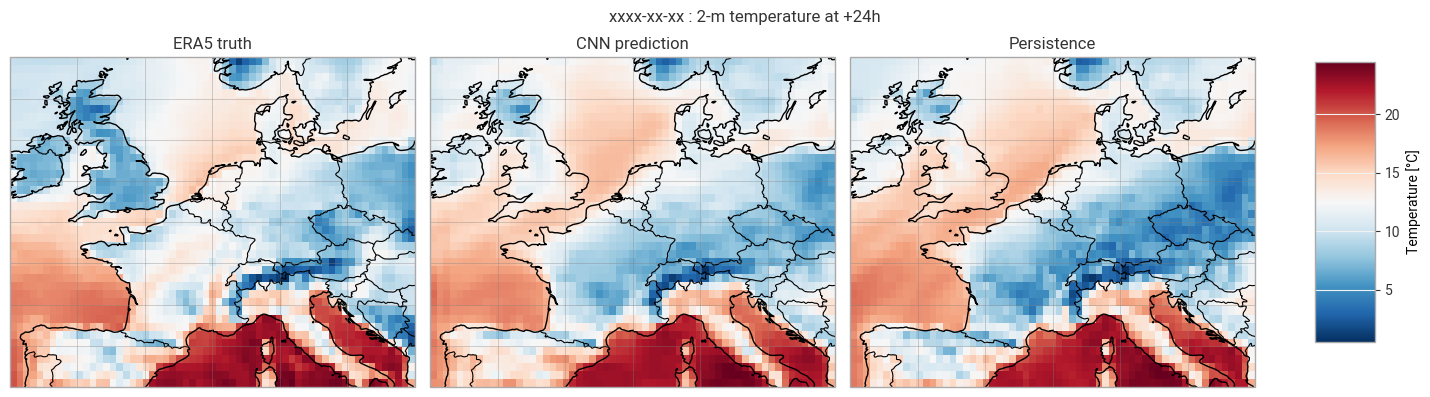

In [47]:
x, y = test_dataset[0]

with torch.no_grad():
    prediction = model(x.unsqueeze(0))

prediction = prediction.squeeze(0)

current_temperature = x[11]

persistence = current_temperature.unsqueeze(0).repeat(4, 1, 1)

##########

lat = ds_normed_zarr.latitude.values
lon = ds_normed_zarr.longitude.values

extent = [lon.min(),lon.max(),lat.min(),lat.max()]

stats = json.loads(ds_normed_zarr.attrs["normalisation_stats"])

horizon = 3

fig, axes = plt.subplots(1, 3, figsize=(15, 4), subplot_kw={"projection": ccrs.PlateCarree()})

axes[0].imshow(y[horizon]*stats['2t']['std']+stats['2t']['mean']-273.15, cmap=plt.cm.RdBu_r, extent=extent, origin="upper", aspect='auto')
axes[0].set_title("ERA5 truth")
axes[0].coastlines()
axes[0].add_feature(cfeature.BORDERS,linewidth=0.8)


axes[1].imshow(prediction[horizon]*stats['2t']['std']+stats['2t']['mean']-273.15, cmap=plt.cm.RdBu_r, extent=extent, origin="upper", aspect='auto')
axes[1].set_title("CNN prediction")
axes[1].coastlines()
axes[1].add_feature(cfeature.BORDERS,linewidth=0.8)

pos1 = axes[2].imshow(persistence[horizon]*stats['2t']['std']+stats['2t']['mean']-273.15, cmap=plt.cm.RdBu_r, extent=extent, origin="upper", aspect='auto')
axes[2].set_title("Persistence")
axes[2].coastlines()
axes[2].add_feature(cfeature.BORDERS,linewidth=0.8)

for ax in axes:
    ax.set_xlabel("Longitude")
    ax.set_ylabel("Latitude")

axes[2].set_xlabel("Longitude")
axes[2].set_xlabel("Longitude")

axes[0].gridlines(draw_labels=False,linewidth=0.5, color='gray', alpha=0.5, linestyle='-')
axes[1].gridlines(draw_labels=False,linewidth=0.5, color='gray', alpha=0.5, linestyle='-')
axes[2].gridlines(draw_labels=False,linewidth=0.5, color='gray', alpha=0.5, linestyle='-')


# add space for colour bar
cbar_ax = fig.add_axes([0.88, 0.15, 0.04, 0.7])
fig.colorbar(pos1, label = 'Temperature [°C]', cax=cbar_ax)
fig.tight_layout(rect=[0, 0, 0.85, 0.95])

#plt.tight_layout()
fig.suptitle('xxxx-xx-xx : 2-m temperature at +24h') # or plt.suptitle('Main title')
plt.show()

In [ ]:
horizon = 3

cnn_error = prediction[horizon] - y[horizon]

persistence_error = persistence[horizon] - y[horizon]

fig, axes = plt.subplots(1, 2, figsize=(10, 4), subplot_kw={"projection": ccrs.PlateCarree()})
norm = mcolors.TwoSlopeNorm(vmin=-12.5, vcenter=0, vmax = 5)

pos1 = axes[0].imshow(cnn_error*stats['2t']['std'], cmap=plt.cm.RdBu_r, norm=norm, extent=extent, origin="upper", aspect='auto')
axes[0].set_title("CNN error")
axes[0].coastlines()
axes[0].add_feature(cfeature.BORDERS,linewidth=0.8)

axes[1].imshow(persistence_error*stats['2t']['std'], cmap=plt.cm.RdBu_r, norm=norm, extent=extent, origin="upper", aspect='auto')
axes[1].set_title("Persistence error")
axes[1].coastlines()
axes[1].add_feature(cfeature.BORDERS,linewidth=0.8)

for ax in axes:
    ax.set_xlabel("Longitude")
    ax.set_ylabel("Latitude")

cbar_ax = fig.add_axes([0.88, 0.15, 0.04, 0.7])
fig.colorbar(pos1, label = 'Temperature difference [K]', cax=cbar_ax)
fig.tight_layout(rect=[0, 0, 0.85, 0.95])

fig.suptitle('xxxx-xx-xx : 2-m temperature at +24h') # or plt.suptitle('Main title')
plt.show()